# Logger session overview: head angle, cameras, spikes
`2026-09-09_15-15_rPG007_P1500_RobotInteract_45min`: wireless Intan512 logger, 6 Basler cameras, IMU-based head orientation, JRClust spikes.

Everything here is read through the analysisVR modality loaders (`session_modality_from_nas`); no analytics are computed or written.
Spikes are extracted in memory with `ephys_preprocessing.postproc_logger_ephys.extract_jrc_spikes_logger`.

**Timebase.** Every table carries `<m>_ephys_timestamp` in µs on the ephys clock (`sample_id * 50`; cameras keep the exact IR-burst onset).
Ephys time contains 47 spurious 192 ms zero pads, so it runs ahead of real time after 263 s; all modalities share it, so they align with each other.
See the session `README.md` and the `problem_intervals` / `timebase_segments` keys.

In [1]:
import os, sys
REPO = os.path.abspath('..')                      # this notebook lives in analysisVR/scripted_plotting
sys.path.insert(0, REPO); sys.path.insert(0, os.path.dirname(REPO))   # analysisVR, and VirtualReality (baseVR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import analytics_processing.sessions_from_nas_parsing as sp
from analytics_processing.modality_loading import session_modality_from_nas as load
from ephys_preprocessing.postproc_logger_ephys import extract_jrc_spikes_logger

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

SESSION = '2026-09-09_15-15_rPG007_P1500_RobotInteract_45min'
try:
    F = sp.sessionnames2fullfnames([SESSION])[0][0]
except (ValueError, IndexError):
    # baseVR.device_paths() does not know every user/OS combination, fall back to the NAS path
    F = ('/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/'
         f'{SESSION}/{SESSION}.hdf5')
print(F)
with pd.HDFStore(F, 'r') as store:
    print(store.keys())

Could not import mea1k_modules.mea1k_post_processing. Make sure ephysVR repository is available.


/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min.hdf5


['/barometer', '/cam1_packages', '/cam2_packages', '/cam3_packages', '/cam4_packages', '/cam5_packages', '/cam6_packages', '/gap_classification', '/imu', '/ir_sync', '/luxmeter', '/magnetometer', '/metadata', '/orientation', '/power', '/problem_intervals', '/timebase_segments']


## 1. Modalities and problem intervals

In [2]:
meta = load(F, 'metadata')
print({k: meta[k] for k in ('session_name', 'paradigm_id', 'animal_id', 'start_time', 'duration_minutes') if k in meta})

ori = load(F, 'orientation')
cams = {k: load(F, f'cam{k}_packages') for k in range(1, 7)}
problems = load(F, 'problem_intervals')
segments = load(F, 'timebase_segments')
traces, mapping = load(F, 'ephys_traces')       # memmap (512 ch, samples) + mapping (row = channel)
N_SAMPLES = traces.shape[1]

summary = []
for key, col in [('imu', 'imu'), ('magnetometer', 'magnetometer'), ('barometer', 'barometer'), ('luxmeter', 'luxmeter'),
                 ('power', 'power'), ('orientation', 'orientation'), ('ir_sync', 'ir_sync'), ('cam1_packages', 'cam1_image')]:
    t = load(F, key, columns=[f'{col}_ephys_timestamp'])[f'{col}_ephys_timestamp'].values
    if key == 'imu':
        t_imu_all = t / 1e6           # kept to select IMU row ranges by time below
    summary.append({'key': key, 'rows': len(t), 'first_s': t[0] / 1e6, 'last_s': t[-1] / 1e6,
                    'median_rate_Hz': 1e6 / np.median(np.diff(t))})
summary.append({'key': 'ephys_traces', 'rows': N_SAMPLES, 'first_s': 0, 'last_s': (N_SAMPLES - 1) / 20_000, 'median_rate_Hz': 20_000})
pd.DataFrame(summary).round(3)

{'session_name': '2026-09-09_15-15_rPG007_P1500_RobotInteract_45min', 'paradigm_id': 1500, 'animal_id': 7, 'start_time': '2026-09-09_15-15', 'duration_minutes': 45}


,key,rows,first_s,last_s,median_rate_Hz
0,imu,17318456,0.000,2752.624,6666.667
1,magnetometer,270602,0.004,2752.621,98.522
2,barometer,270602,0.004,2752.621,98.522
3,luxmeter,270602,0.005,2752.622,100.000
4,power,2742448,0.000,2752.623,1000.000
5,orientation,275263,0.000,2752.620,100.000
6,ir_sync,81042,1.724,2748.712,30.001
7,cam1_packages,81000,1.724,2710.697,30.001
8,ephys_traces,55052479,0.000,2752.624,20000.000


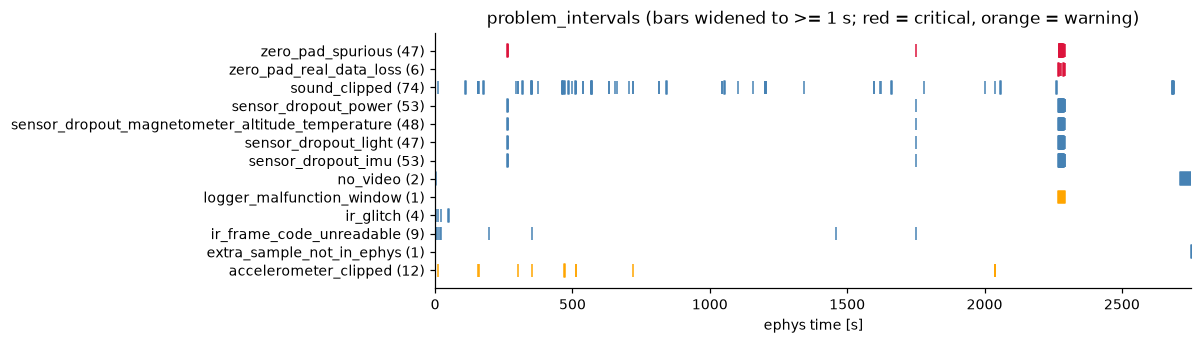

In [3]:
pads = problems[problems.category.str.startswith('zero_pad')]
malfunction = problems[problems.category == 'logger_malfunction_window']

def shade_problems(ax, t_unit=1e6, label=True):
    """Shade zero pads (red: real data loss, grey: spurious) and the malfunction window on a time axis in s."""
    for _, r in malfunction.iterrows():
        ax.axvspan(r.start_sample * 50 / t_unit, r.end_sample * 50 / t_unit, color='orange', alpha=.15, lw=0,
                   label='malfunction window' if label else None)
    for _, r in pads.iterrows():
        real = r.category == 'zero_pad_real_data_loss'
        ax.axvline(r.start_sample * 50 / t_unit, color='crimson' if real else 'grey', lw=.6, alpha=.8 if real else .4)

cats = problems.groupby('category')
fig, ax = plt.subplots(figsize=(11, 3.2))
for i, (cat, d) in enumerate(cats):
    s, e = d.start_sample.values / 20_000, (d.end_sample.values + 1) / 20_000
    ax.broken_barh(list(zip(s, np.maximum(e - s, 1.0))), (i - .35, .7), color='crimson' if 'critical' in d.severity.values else
                   'orange' if 'warning' in d.severity.values else 'steelblue')   # min width 1 s so short ones are visible
ax.set_yticks(range(len(cats))); ax.set_yticklabels([f'{c} ({len(d)})' for c, d in cats])
ax.set_xlabel('ephys time [s]'); ax.set_title('problem_intervals (bars widened to >= 1 s; red = critical, orange = warning)')
ax.set_xlim(0, N_SAMPLES / 20_000); plt.tight_layout()

## 2. Head angle (`orientation`, 100 Hz, IMU fusion)
Yaw/pitch/roll in degrees. `orientation_ephys_patched == 1` marks samples interpolated across zero pads.

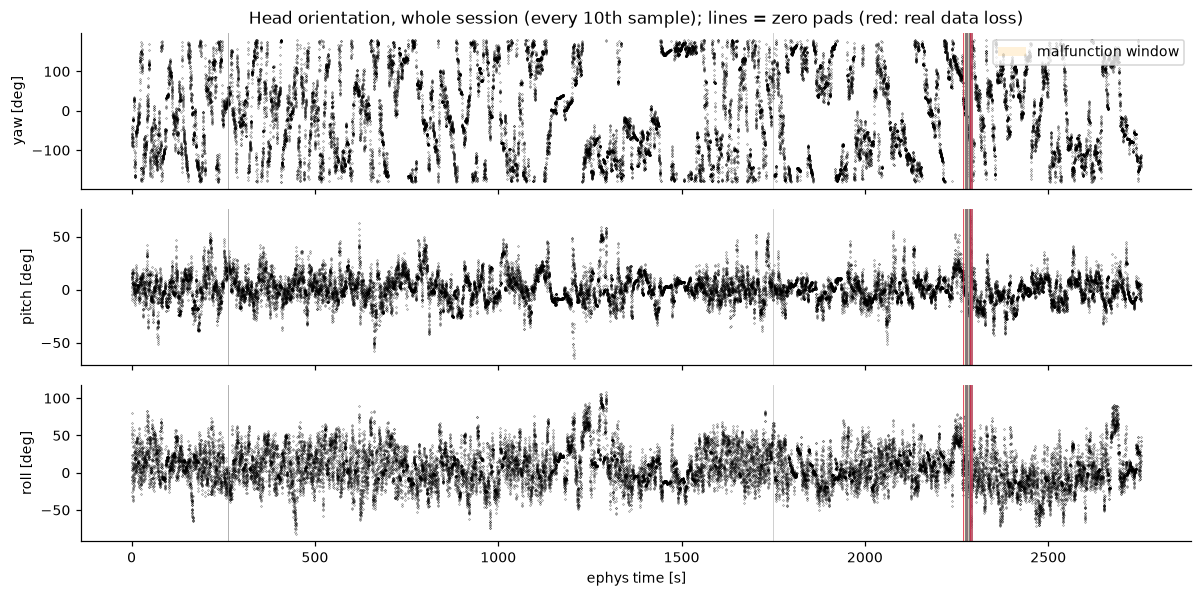

In [4]:
t_ori = ori.orientation_ephys_timestamp.values / 1e6
fig, axes = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True)
for ax, c in zip(axes, ['yaw', 'pitch', 'roll']):
    ax.plot(t_ori[::10], ori[f'orientation_{c}'].values[::10], '.', ms=.4, color='k')   # dots: yaw wraps at +-180
    shade_problems(ax, label=c == 'yaw'); ax.set_ylabel(f'{c} [deg]')
axes[0].legend(loc='upper right'); axes[-1].set_xlabel('ephys time [s]')
axes[0].set_title('Head orientation, whole session (every 10th sample); lines = zero pads (red: real data loss)')
plt.tight_layout()

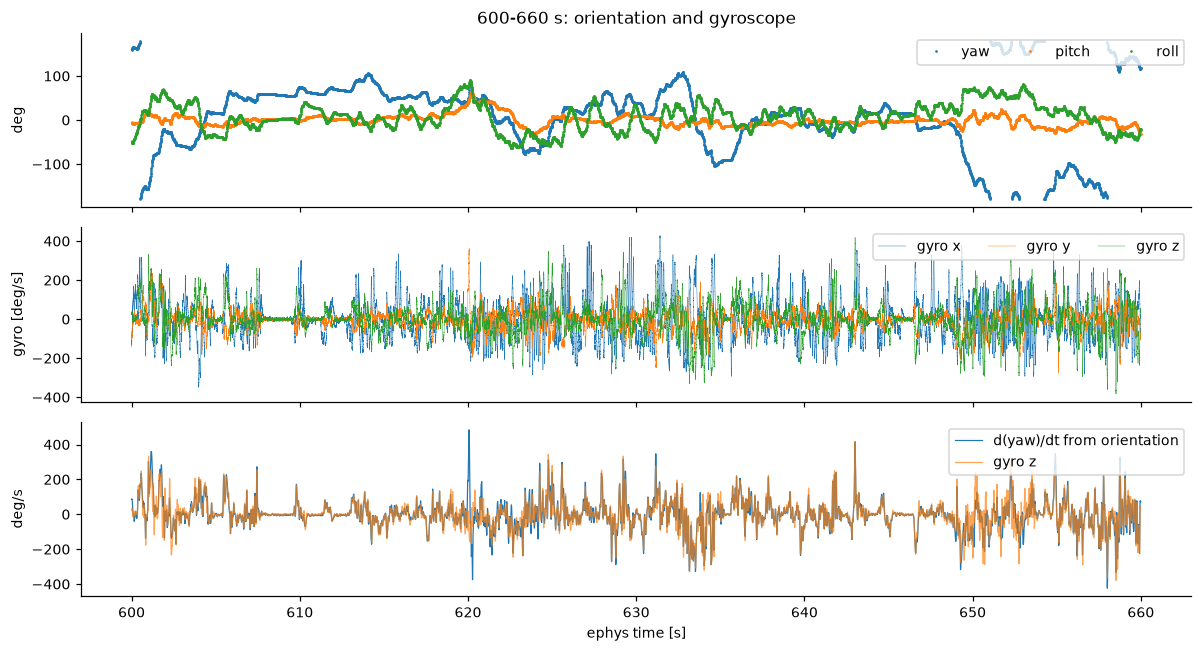

In [5]:
# zoom: 60 s, orientation vs the raw gyroscope (6.67 kHz) in the same window
t0, t1 = 600, 660
imu = load(F, 'imu', start=int(np.searchsorted(t_imu_all, t0)), stop=int(np.searchsorted(t_imu_all, t1)))   # tables have no where-index
w = (t_ori >= t0) & (t_ori < t1)
yaw_unwr = np.rad2deg(np.unwrap(np.deg2rad(ori.orientation_yaw.values)))
yaw_rate = np.gradient(yaw_unwr, t_ori)       # deg/s

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for c in ['yaw', 'pitch', 'roll']:
    axes[0].plot(t_ori[w], ori[f'orientation_{c}'].values[w], '.', ms=1.5, label=c)
axes[0].set_ylabel('deg'); axes[0].legend(ncol=3, loc='upper right')
for c in 'xyz':
    axes[1].plot(imu.imu_ephys_timestamp / 1e6, np.rad2deg(imu[f'imu_gyro_{c}']), lw=.3, label=f'gyro {c}')
axes[1].set_ylabel('gyro [deg/s]'); axes[1].legend(ncol=3, loc='upper right')
gz = np.interp(t_ori[w], imu.imu_ephys_timestamp / 1e6, np.rad2deg(imu.imu_gyro_z))
axes[2].plot(t_ori[w], yaw_rate[w], lw=.8, label='d(yaw)/dt from orientation')
axes[2].plot(t_ori[w], gz, lw=.8, alpha=.7, label='gyro z')
axes[2].set_ylabel('deg/s'); axes[2].legend(loc='upper right'); axes[2].set_xlabel('ephys time [s]')
axes[0].set_title(f'{t0}-{t1} s: orientation and gyroscope'); plt.tight_layout()

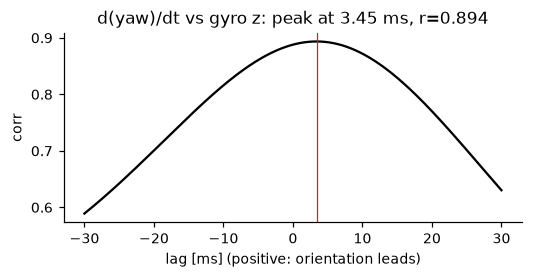

In [6]:
# lag between orientation and gyroscope: yaw-rate interpolated onto the IMU timestamps, cross-correlated with the gyro axis
# that best matches it (positive lag = orientation leads). The README states ~4-4.5 ms (~90 ephys samples).
t_imu = imu.imu_ephys_timestamp.values / 1e6
yr = np.interp(t_imu, t_ori, yaw_rate)
best = max('xyz', key=lambda c: abs(np.corrcoef(yr, imu[f'imu_gyro_{c}'])[0, 1]))
g = np.rad2deg(imu[f'imu_gyro_{best}'].values) * np.sign(np.corrcoef(yr, imu[f'imu_gyro_{best}'])[0, 1])
lags = np.arange(-200, 201)     # IMU samples (150 us each)
xc = [np.corrcoef(yr[200:len(yr) - 200], g[200 + l:len(g) - 200 + l])[0, 1] for l in lags]   # yaw-rate(t) vs gyro(t + lag)
dt_imu = np.median(np.diff(t_imu))
lag_ms = lags[np.argmax(xc)] * dt_imu * 1e3
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(lags * dt_imu * 1e3, xc, color='k'); ax.axvline(lag_ms, color='crimson', lw=.8)
ax.set_xlabel('lag [ms] (positive: orientation leads)'); ax.set_ylabel('corr')
ax.set_title(f'd(yaw)/dt vs gyro {best}: peak at {lag_ms:.2f} ms, r={max(xc):.3f}'); plt.tight_layout()

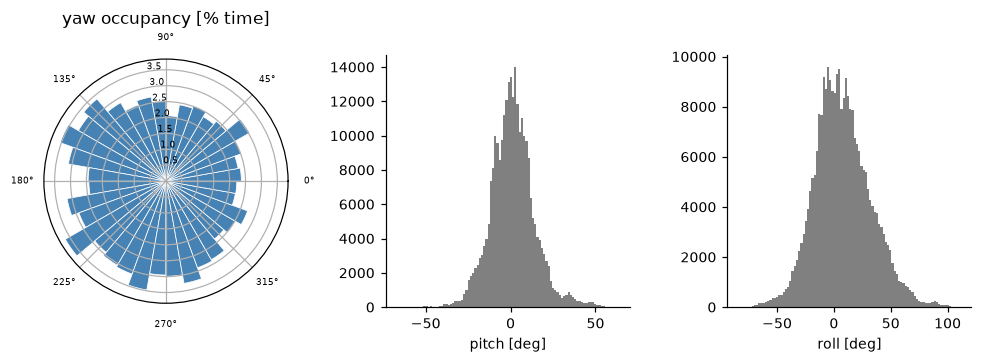

In [7]:
# head-direction occupancy, excluding interpolated samples and the malfunction window
def in_intervals(sample_ids, iv):
    a, b = np.sort(iv.start_sample.values), iv.end_sample.values[np.argsort(iv.start_sample.values)]
    k = np.searchsorted(a, sample_ids, side='right') - 1
    return (k >= 0) & (sample_ids <= b[np.clip(k, 0, None)])

clean_ori = (ori.orientation_ephys_patched.values == 0) & ~in_intervals(ori.orientation_sample_id.values, malfunction)
fig = plt.figure(figsize=(9, 3.2))
ax = fig.add_subplot(131, projection='polar')
h, e = np.histogram(np.deg2rad(ori.orientation_yaw.values[clean_ori]), bins=36, range=(-np.pi, np.pi))
ax.bar(e[:-1], h / clean_ori.sum() * 100, width=np.diff(e), align='edge', color='steelblue', edgecolor='white', lw=.5)
ax.tick_params(labelsize=6); ax.set_rlabel_position(100)
ax.set_title('yaw occupancy [% time]')
for i, c in enumerate(['pitch', 'roll']):
    ax = fig.add_subplot(1, 3, i + 2)
    ax.hist(ori[f'orientation_{c}'].values[clean_ori], bins=100, color='grey'); ax.set_xlabel(f'{c} [deg]')
plt.tight_layout()

## 3. Cameras (`cam1_packages` ... `cam6_packages`)
All six cameras are triggered by the same Arduino pulse, so row *k* of every table is mp4 frame *k* and they share `image_ephys_timestamp`.

In [8]:
c1 = cams[1]
assert all(np.array_equal(cams[k][f'cam{k}_image_ephys_timestamp'].values, c1.cam1_image_ephys_timestamp.values) for k in cams)
pd.DataFrame({f'cam{k}': {'frames': len(c), 'sync ir_decoded': (c[f'cam{k}_image_sync_source'] == 'ir_decoded').sum(),
                          'sync interpolated (patched)': int(c[f'cam{k}_image_ephys_patched'].sum()),
                          'in real data loss': int(c[f'cam{k}_image_ephys_missing'].sum()),
                          'in malfunction window': int(c[f'cam{k}_image_in_malfunction_window'].sum())}
              for k, c in cams.items()})

,cam1,cam2,cam3,cam4,cam5,cam6
frames,81000,81000,81000,81000,81000,81000
sync ir_decoded,80936,80936,80936,80936,80936,80936
sync interpolated (patched),61,61,61,61,61,61
in real data loss,34,34,34,34,34,34
in malfunction window,471,471,471,471,471,471


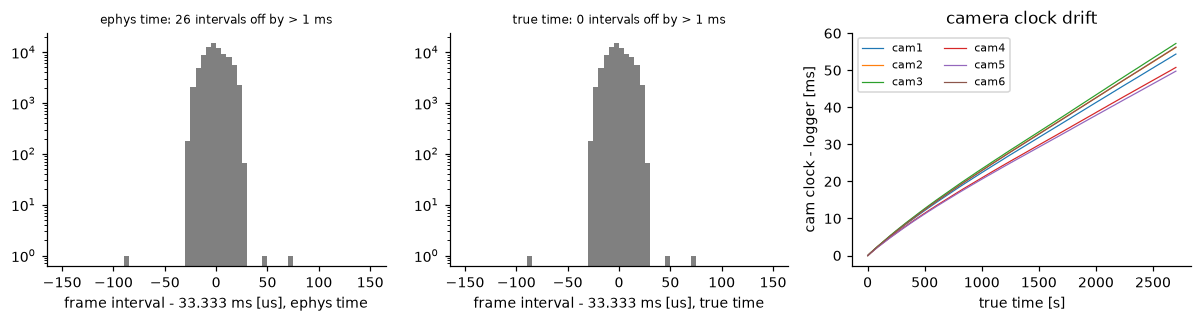

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
d_eph = np.diff(c1.cam1_image_ephys_timestamp.values) / 1e3
d_true = np.diff(c1.cam1_image_true_timestamp.values) / 1e3
for ax, d, nm in [(axes[0], d_eph, 'ephys time'), (axes[1], d_true, 'true time')]:
    ax.hist((d - 1e3 / 30) * 1e3, bins=np.arange(-150, 151, 5), color='grey'); ax.set_yscale('log')
    ax.set_xlabel(f'frame interval - 33.333 ms [us], {nm}')
    ax.set_title(f'{nm}: {(np.abs(d - 1e3 / 30) > 1).sum()} intervals off by > 1 ms', fontsize=8)
# camera hardware clocks vs logger true time (drift relative to the logger clock)
for k, c in cams.items():
    res = (c[f'cam{k}_image_cam_timestamp'] - (c[f'cam{k}_image_true_timestamp'] - c[f'cam{k}_image_true_timestamp'].iloc[0])) / 1e3
    axes[2].plot(c[f'cam{k}_image_true_timestamp'][::30] / 1e6, res[::30], lw=.8, label=f'cam{k}')
axes[2].set_xlabel('true time [s]'); axes[2].set_ylabel('cam clock - logger [ms]'); axes[2].legend(ncol=2, fontsize=7)
axes[2].set_title('camera clock drift'); plt.tight_layout()

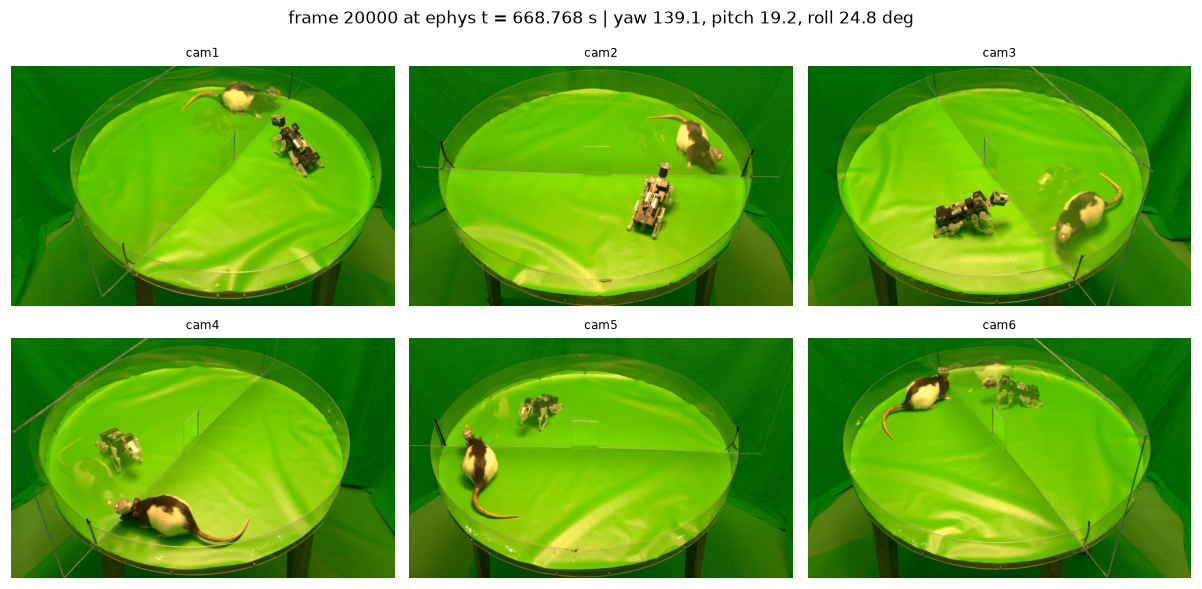

In [10]:
# one synchronized frame from every camera, with the head orientation at that moment
D = os.path.dirname(F)
frame_id = 20_000
ts = c1.cam1_image_ephys_timestamp.values[frame_id]
oi = np.searchsorted(ori.orientation_ephys_timestamp.values, ts)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, k in zip(axes.ravel(), cams):
    cap = cv2.VideoCapture(os.path.join(D, f'cam{k}.mp4'))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ok, img = cap.read(); pos = cap.get(cv2.CAP_PROP_POS_FRAMES) - 1; cap.release()
    assert ok and pos == frame_id
    ax.imshow(img[..., ::-1]); ax.set_axis_off(); ax.set_title(f'cam{k}', fontsize=8)
fig.suptitle(f'frame {frame_id} at ephys t = {ts / 1e6:.3f} s | yaw {ori.orientation_yaw.values[oi]:.1f}, '
             f'pitch {ori.orientation_pitch.values[oi]:.1f}, roll {ori.orientation_roll.values[oi]:.1f} deg')
plt.tight_layout()

## 4. Spikes (JRClust, curated)
`extract_jrc_spikes_logger` maps JRClust sites to `.dat` channels with the prm `siteMap`, uses `sample_id = spikeTimes - 1`,
drops clusters without a label or labelled `to_delete`, removes same-cluster spikes <= 1 ms apart (the duplicate spikes on a second site),
and flags spikes inside / within 5 ms of a zero pad. `gross_brain_area` is a placeholder (= shank name) until histology.

In [11]:
clusters, spikes = extract_jrc_spikes_logger(F)
print(len(spikes), 'spikes', clusters.cluster_type.value_counts().to_dict())
print('in zero pad:', int(spikes.in_zero_pad.sum()), ' within 5 ms of a pad:', int(spikes.within_5ms_of_pad.sum()),
      ' in malfunction window:', int(spikes.in_malfunction_window.sum()))
clusters.groupby(['shank_name', 'cluster_type']).size().unstack(fill_value=0)

4386219 spikes {'single': 186, 'noise': 39}
in zero pad: 873  within 5 ms of a pad: 2759  in malfunction window: 36345


cluster_type,noise,single
shank_name,,
shank1,0,4
shank2,0,27
shank3,0,46
shank4,39,35
shank5,0,9
shank6,0,18
shank7,0,23
shank8,0,24


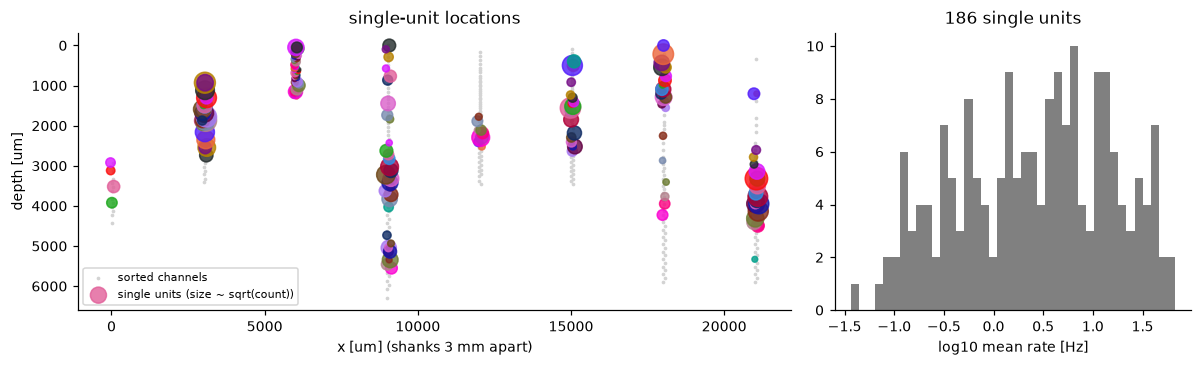

In [12]:
single = clusters[clusters.cluster_type == 'single']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
used = mapping[mapping.curated_trace]
ax.scatter(used.x, used.depth, s=2, color='lightgrey', label='sorted channels')
rng = np.random.default_rng(0)
ax.scatter(single.x + rng.uniform(-80, 80, len(single)), single.depth, s=np.sqrt(single.session_spike_count) / 2,
           c=single.cluster_color, alpha=.8, label='single units (size ~ sqrt(count))')
ax.set_xlabel('x [um] (shanks 3 mm apart)'); ax.set_ylabel('depth [um]'); ax.invert_yaxis(); ax.legend(fontsize=7)
ax.set_title('single-unit locations')
ax = axes[1]
rate = single.session_spike_count / (N_SAMPLES / 20_000)
ax.hist(np.log10(rate), bins=40, color='grey'); ax.set_xlabel('log10 mean rate [Hz]'); ax.set_title(f'{len(single)} single units')
plt.tight_layout()

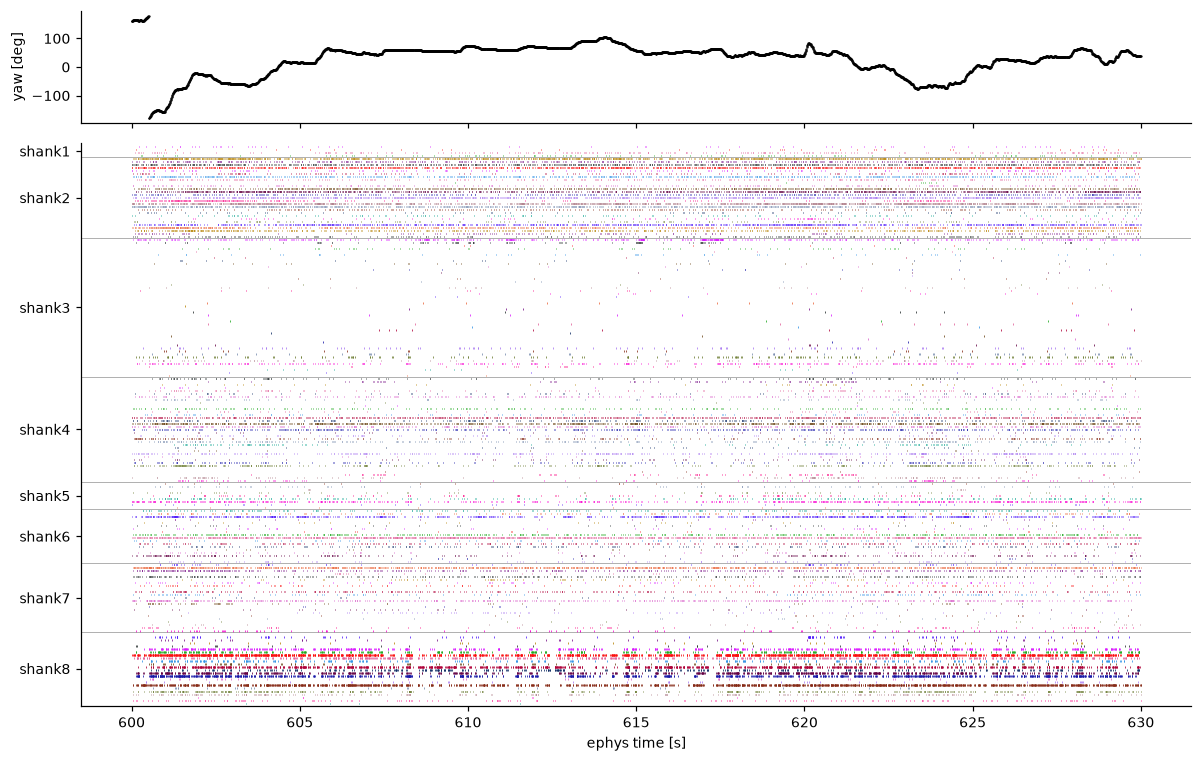

In [13]:
# raster for 30 s, single units sorted by shank and depth, with head yaw on top
t0, t1 = 600, 630
order = single.sort_values(['shank_id', 'depth']).cluster_id.values
row_of = {c: i for i, c in enumerate(order)}
s = spikes[(spikes.ephys_timestamp >= t0 * 1e6) & (spikes.ephys_timestamp < t1 * 1e6) & spikes.cluster_id.isin(row_of)]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1, 5]})
w = (t_ori >= t0) & (t_ori < t1)
axes[0].plot(t_ori[w], ori.orientation_yaw.values[w], '.', ms=1, color='k'); axes[0].set_ylabel('yaw [deg]')
axes[1].scatter(s.ephys_timestamp / 1e6, s.cluster_id.map(row_of), s=.6, c=s.cluster_color, marker='|', lw=.5)
sh = single.sort_values(['shank_id', 'depth']).shank_name.values
for i in np.flatnonzero(sh[1:] != sh[:-1]):
    axes[1].axhline(i + .5, color='grey', lw=.4)
axes[1].set_yticks([np.mean(np.flatnonzero(sh == n)) for n in pd.unique(sh)]); axes[1].set_yticklabels(pd.unique(sh))
axes[1].set_xlabel('ephys time [s]'); axes[1].set_ylim(len(order), -1); plt.tight_layout()

Text(0.5, 0, 'ephys time [s]')

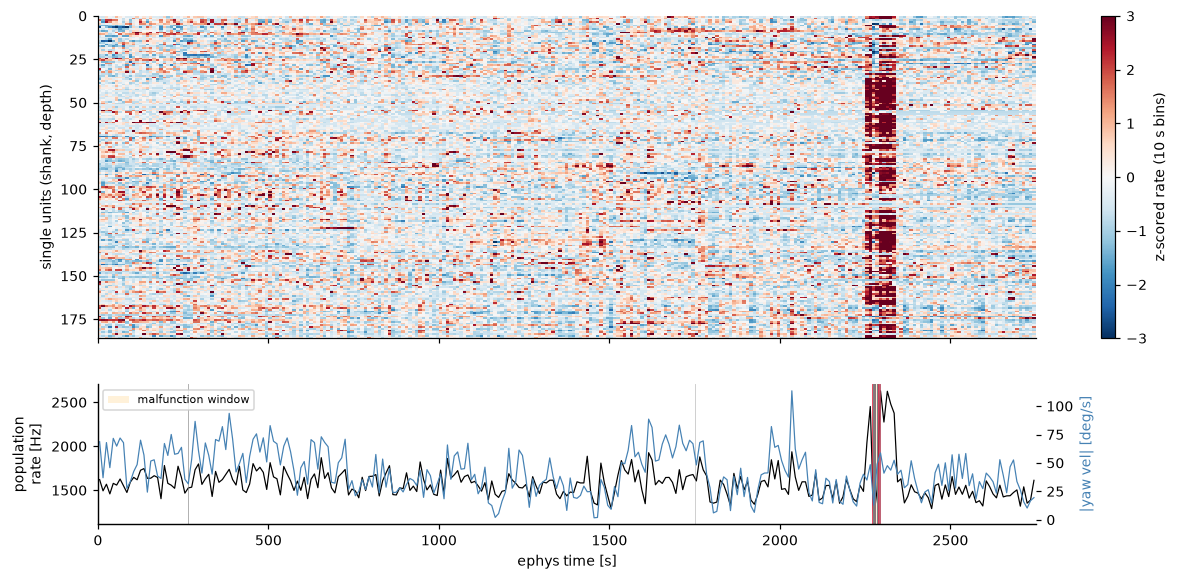

In [14]:
# firing rate stability over the session: single units, 10 s bins, z-scored per unit
edges = np.arange(0, N_SAMPLES * 50, 10e6)    # last partial bin dropped
sg = spikes[spikes.cluster_id.isin(row_of)]
H = np.zeros((len(order), len(edges) - 1))
hb = np.searchsorted(edges, sg.ephys_timestamp.values, side='right') - 1; hk = hb < len(edges) - 1
np.add.at(H, (sg.cluster_id.map(row_of).values[hk], hb[hk]), 1)
Z = (H - H.mean(1, keepdims=True)) / (H.std(1, keepdims=True) + 1e-9)
tb = np.searchsorted(edges, ori.orientation_ephys_timestamp.values, side='right') - 1; okb = (tb >= 0) & (tb < len(edges) - 1)
head_speed = np.bincount(tb[okb], np.abs(yaw_rate[okb]), len(edges) - 1) / np.maximum(np.bincount(tb[okb], minlength=len(edges) - 1), 1)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ax = axes[0]
im = ax.imshow(Z, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, extent=(0, edges[-1] / 1e6, len(order), 0), interpolation='none')
plt.colorbar(im, cax=ax.inset_axes([1.07, 0, .015, 1]), label='z-scored rate (10 s bins)')
ax.set_ylabel('single units (shank, depth)')
ax = axes[1]; tc = (edges[:-1] + 5e6) / 1e6
ax.plot(tc, H.sum(0) / 10, color='k', lw=.8); ax.set_ylabel('population\nrate [Hz]')
ax2 = ax.twinx(); ax2.plot(tc, head_speed, color='steelblue', lw=.8); ax2.set_ylabel('|yaw vel| [deg/s]', color='steelblue')
shade_problems(ax, label=True); ax.legend(loc='upper left', fontsize=7); ax.set_xlabel('ephys time [s]')

Population rate rises to ~1.6x baseline at 2255-2270 s and 2290-2335 s on all shanks, around the logger malfunction window
(2268.7-2292.8 s). Raw-trace RMS is unchanged there, so it is not an obvious noise artefact; check behaviour/video before using it.

## 5. Joined 40 ms table: spikes + head angle + cameras
Bins follow `FiringRate40msHz`: edges every 40 ms from 0, right-closed `(from, to]` on `ephys_timestamp` [µs].
Per bin: spike counts per single unit, circular-mean yaw, mean pitch/roll, mean absolute yaw velocity, the first camera frame
(`cam_image_id`, same for all 6 cameras) and the number of frames, and problem flags.

In [15]:
BIN = 40_000
edges = np.arange(0, spikes.ephys_timestamp.max() + BIN, BIN, dtype=np.uint64)
n_bins = len(edges) - 1
def bin_of(ts_us):          # (from, to] bins; -1 / n_bins = outside
    return np.ceil(np.asarray(ts_us, dtype=np.float64) / BIN).astype(np.int64) - 1

# spikes
b = bin_of(sg.ephys_timestamp.values); k = (b >= 0) & (b < n_bins)
counts = np.zeros((n_bins, len(order)), np.uint16)
np.add.at(counts, (b[k], sg.cluster_id.map(row_of).values[k]), 1)
unit_cols = single.set_index('cluster_id').loc[order, 'cluster_id_str'].values

# orientation
ob = bin_of(ori.orientation_ephys_timestamp.values); ok = (ob >= 0) & (ob < n_bins)
def bin_mean(v):
    s_ = np.bincount(ob[ok], weights=v[ok], minlength=n_bins); n_ = np.bincount(ob[ok], minlength=n_bins)
    return np.where(n_ > 0, s_ / np.maximum(n_, 1), np.nan)
yaw_r = np.deg2rad(ori.orientation_yaw.values)
head = pd.DataFrame({
    'head_yaw': np.rad2deg(np.arctan2(bin_mean(np.sin(yaw_r)), bin_mean(np.cos(yaw_r)))),
    'head_pitch': bin_mean(ori.orientation_pitch.values), 'head_roll': bin_mean(ori.orientation_roll.values),
    'head_yaw_abs_vel': bin_mean(np.abs(yaw_rate)),
    'head_patched': bin_mean(ori.orientation_ephys_patched.values.astype(float)) > 0})

# cameras: first frame in the bin
cb = bin_of(c1.cam1_image_ephys_timestamp.values); ck = (cb >= 0) & (cb < n_bins)
first_frame = pd.Series(c1.cam1_image_id.values[ck]).groupby(cb[ck]).first()
cam = pd.DataFrame({'cam_image_id': first_frame.reindex(range(n_bins)).astype('Int64').values,
                    'cam_n_frames': np.bincount(cb[ck], minlength=n_bins)})

# problem flags: does the bin (from, to] overlap an interval [start_sample, end_sample]
def overlaps(iv):
    m = np.zeros(n_bins + 1, int)
    lo = np.clip(bin_of(iv.start_sample.values * 50), 0, n_bins); hi = np.clip(bin_of(iv.end_sample.values * 50), 0, n_bins - 1)
    np.add.at(m, lo, 1); np.add.at(m, hi + 1, -1)
    return np.cumsum(m)[:n_bins] > 0
flags = pd.DataFrame({'in_zero_pad': overlaps(pads), 'in_real_data_loss': overlaps(pads[pads.category == 'zero_pad_real_data_loss']),
                      'in_malfunction_window': overlaps(malfunction)})

joined = pd.concat([pd.DataFrame({'from_ephys_timestamp': edges[:-1], 'to_ephys_timestamp': edges[1:]}),
                    head, cam, flags, pd.DataFrame(counts, columns=unit_cols)], axis=1)
joined['clean'] = ~(joined.in_zero_pad | joined.in_malfunction_window | joined.head_patched)
print(joined.shape, ' clean bins:', int(joined.clean.sum()))
joined.iloc[15_000:15_005, :16]

(68816, 199)  clean bins: 68196


,from_ephys_timestamp,to_ephys_timestamp,head_yaw,head_pitch,head_roll,head_yaw_abs_vel,head_patched,cam_image_id,cam_n_frames,in_zero_pad,in_real_data_loss,in_malfunction_window,Unit0004,Unit0003,Unit0001,Unit0002
15000,600000000,600040000,161.033529,-5.638110,-49.721856,87.241776,False,17937,2,False,False,False,0,0,0,0
15001,600040000,600080000,164.052560,-7.222654,-51.818344,49.492203,False,17939,1,False,False,False,0,0,0,0
15002,600080000,600120000,164.848098,-8.468664,-49.461343,4.277580,False,17940,1,False,False,False,0,0,1,0
15003,600120000,600160000,164.684617,-8.283248,-44.233609,15.845924,False,17941,1,False,False,False,0,1,0,0
15004,600160000,600200000,163.507718,-7.495161,-41.768737,28.385267,False,17942,1,False,False,False,0,0,0,0


In [16]:
# sanity: spike counts in the joined table equal the spike table; frames in bins equal the frame table
assert counts.sum() == ((sg.ephys_timestamp > 0) & (sg.ephys_timestamp <= edges[-1])).sum()
assert joined.cam_n_frames.sum() == ck.sum()
print('bins with 1 / 2 frames:', joined.cam_n_frames.value_counts().sort_index().to_dict())

bins with 1 / 2 frames: {0: 1311, 1: 54010, 2: 13495}


3 / 186 single units exceed the 99th percentile of their shuffled mean vector length


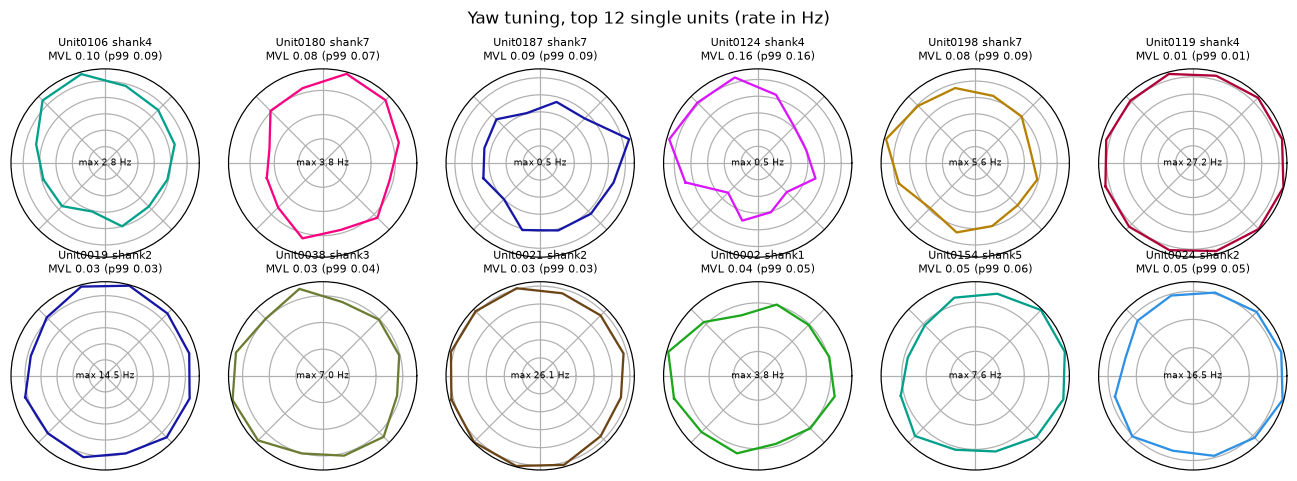

In [17]:
# head-direction tuning (yaw, 12 x 30 deg) of single units on clean bins, against a circular time-shift shuffle
J = joined[joined.clean & joined.head_yaw.notna()]
yb = np.clip(((J.head_yaw.values + 180) // 30).astype(int), 0, 11)
onehot = np.eye(12)[yb]                                   # bins x 12
occ_s = onehot.sum(0) * BIN / 1e6                         # seconds per yaw bin
C = J[unit_cols].values.astype(float)
def tuning(Cm): return (onehot.T @ Cm) / occ_s[:, None]  # Hz, 12 x units
ang = np.deg2rad(np.arange(12) * 30 - 165)
def mvl(T): return np.abs((T * np.exp(1j * ang)[:, None]).sum(0)) / T.sum(0)
T = tuning(C); r = mvl(T)
rng = np.random.default_rng(1)
null = np.array([mvl(tuning(np.roll(C, rng.integers(750, len(C) - 750), axis=0))) for _ in range(200)])   # shifts >= 30 s
p99 = np.nanpercentile(null, 99, axis=0)
sig = r > p99
print(f'{sig.sum()} / {len(r)} single units exceed the 99th percentile of their shuffled mean vector length')

top = np.argsort(-np.nan_to_num(r - p99))[:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4), subplot_kw={'projection': 'polar'})
for ax, u in zip(axes.ravel(), top):
    ax.plot(np.r_[ang, ang[0]], np.r_[T[:, u], T[0, u]], color=single.set_index('cluster_id').loc[order[u], 'cluster_color'])
    ax.set_title(f'{unit_cols[u]} {single.set_index("cluster_id").loc[order[u], "shank_name"]}\nMVL {r[u]:.2f} (p99 {p99[u]:.2f})', fontsize=7)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.text(0, 0, f'max {T[:, u].max():.1f} Hz', ha='center', va='center', fontsize=6)
fig.suptitle('Yaw tuning, top 12 single units (rate in Hz)'); plt.tight_layout()

Notes
- Yaw comes from IMU fusion; its absolute reference can drift over the session, so tuning is only meaningful where yaw is stable.
- Orientation leads the gyroscope by a few ms (section 2); it was left uncorrected.
- Spikes inside zero pads are artefacts: use `clean`, `in_zero_pad` or the spike flags to drop them.